# Analyse saved VGGT experiments
This notebook reads **saved inference outputs only**. It does not import PyTorch/VGGT, load model weights, reopen the full DAVIS dataset, or run inference. It uses NumPy, Matplotlib, Pillow, and Jupyter/IPython. A fresh kernel avoids retaining data from the selection notebook.

Workflow: choose a completed run → watch predicted versus ground-truth tracks → inspect point/frame errors and visibility → optionally define manual point groups or compare runs → explicitly save graphs, tables, and labeled playback for one or all completed runs. Original exports and results remain unchanged.

**Scope:** the runner tracks points visible in its first selected frame, within selected windows. These are exploratory diagnostics, **not official TAP-Vid AJ/APD/OA benchmark scores**. Ranking large errors helps inspect examples, but examples chosen for high error do not establish typical performance. Motion labels and point groups must come from your inspection; they are not inferred automatically.


In [1]:
from pathlib import Path
import gc, json, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

candidates = [Path.cwd(), Path.cwd() / 'AML_project', *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'scripts/vggt_analysis.py').is_file() and (p / 'README.md').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from AML_project, its parent, or a subdirectory.')
if str(PROJECT_ROOT / 'scripts') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
from vggt_analysis import (scan_runs, table_html, load_run, diagnostics, summarize,
                           per_point_rows, per_frame_rows, worst_pairs, group_rows,
                           comparison_player, plot_tracking, plot_geometry, compare_runs, save_analysis)
print('Project:', PROJECT_ROOT)
print('Kernel:', sys.executable)


Project: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project
Kernel: /home/paul/Documents/Cours/Advanced Machine Learning/vggt/venv/bin/python


## 1. Find completed runs
The inventory reads small metadata files, not every prediction archive. Failed/incomplete runs are listed separately and cannot be selected as successful predictions. `seconds` measures inference plus CPU transfer, **not** loading or total wall time. `input_id` is the start of the exported-file hash: matching values identify the same export.


In [2]:
RUNS_ROOT = PROJECT_ROOT / 'results/vggt'
inventory = scan_runs(RUNS_ROOT)
completed = [dict(index=i, **row) for i, row in enumerate(r for r in inventory if r['status'] == 'completed')]
failed = [row for row in inventory if row['status'] != 'completed']
if not completed:
    raise FileNotFoundError(f'No completed runs with predictions and annotations in {RUNS_ROOT}')
display(HTML(table_html(completed, ['index', 'run', 'experiment', 'sequence', 'frames', 'queries', 'device', 'seconds', 'input_id', 'notes'])))
if failed:
    print('Failed/incomplete runs (not included in analysis):')
    display(HTML(table_html(failed, ['run', 'experiment', 'status', 'notes'])))


index,run,experiment,sequence,frames,queries,device,seconds,input_id,notes
0,20261125T150436_740638Z_09d23a,experiment_001,dance-twirl,20,22,cuda:0,4.704,1720674d839a,
1,20261125T150511_264628Z_19dd0b,experiment_001,paragliding-launch,20,23,cuda:0,4.637,1f009861a9c2,
2,20261125T150741_680748Z_cb920c,experiment_001,paragliding-launch,20,23,cpu,119.2,1f009861a9c2,
3,20261125T151026_816269Z_969927,experiment_001,dance-twirl,20,22,cpu,119.8,1720674d839a,


## 2. Choose one run
Set `RUN_INDEX` to a row from the completed-run table. Default: latest completed run. Only tracking arrays and preprocessed RGB inputs are loaded initially; dense geometry stays on disk until the optional geometry section. RGB is held as uint8 for viewing.

Changing runs resets previous figures, group definitions, and comparisons. The original point IDs below identify the tracked subset—not necessarily all points exported from the dataset.


In [3]:
RUN_INDEX = len(completed) - 1
if not 0 <= RUN_INDEX < len(completed):
    raise ValueError('Choose an index from the completed-run table.')
for figure in globals().get('figures', {}).values():
    plt.close(figure)
if 'run' in globals():
    del run
gc.collect()
run = load_run(completed[RUN_INDEX]['path'], with_images=True)
figures = {}
POINT_GROUPS = {}
comparison_rows = []
print('Run:', run['path'])
print('Selection:', json.dumps(run['metadata'].get('export_metadata', {}).get('selection', {}), indent=2))
print('Stored frame indices:', run['annotations']['frame_indices'].tolist())
print('Original tracked point IDs:', run['annotations']['point_ids'].tolist())
print('Device:', run['metadata'].get('device'), '| autocast:', run['metadata'].get('autocast_dtype') or 'disabled (FP32)')


Run: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project/results/vggt/20261125T151026_816269Z_969927/experiment_001
Selection: {
  "start_frame": 5,
  "frame_stride": 1,
  "max_frames": 20,
  "point_ids": null,
  "max_points": null,
  "notes": "",
  "name": "experiment_001",
  "sequence": "dance-twirl"
}
Stored frame indices: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Original tracked point IDs: [0, 1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24]
Device: cpu | autocast: disabled (FP32)


## 3. Diagnostic definitions
**Tracking error:** undo VGGT's recorded resize/crop, map normalized coordinates to a canonical **256×256** image, and calculate Euclidean endpoint error (EPE). `mean_epe_source_px` also reports error in the source video's stored pixel coordinates. Neither metric is a physical distance.

Scoring excludes the first input/query frame, GT-occluded points, and GT points outside the model crop. **Predicted confidence/visibility never filters tracking errors.** Non-finite predictions at valid positions count as infinite error and are reported explicitly. Means pool valid point/frame pairs; points visible for longer contribute more pairs. Median/max and per-point counts provide context. No valid pairs gives an empty result, not zero error. Infinite errors cannot be drawn as finite chart heights; inspect the counters and tables.

**Visibility agreement:** compare the model visibility score to `VISIBILITY_THRESHOLD`. Exclude the query frame and GT-visible points outside the crop; include annotated occlusions. Non-finite visibility scores count as incorrect. The always-visible baseline helps reveal class imbalance. This diagnostic is not official TAP-Vid OA, and the threshold is a user setting, not a calibrated guarantee of correctness.


In [4]:
VISIBILITY_THRESHOLD = 0.5
diag = diagnostics(run, VISIBILITY_THRESHOLD)
summary = summarize(run, diag)
display(HTML(table_html([summary], ['points', 'scored_pairs', 'mean_epe_256', 'median_epe_256', 'max_epe_256', 'mean_epe_source_px', 'nonfinite_positions'])))
display(HTML(table_html([summary], ['visibility_pairs', 'visibility_agreement', 'always_visible_baseline', 'nonfinite_visibility'])))


points,scored_pairs,mean_epe_256,median_epe_256,max_epe_256,mean_epe_source_px,nonfinite_positions
22,330,12.64,1.398,73.71,37.55,0


visibility_pairs,visibility_agreement,always_visible_baseline,nonfinite_visibility
418,0.3876,0.7895,0


## 4. Watch ground truth versus predictions
Green dots: visible/in-crop GT. Red crosses: finite predictions. Yellow lines: displacement where GT is visible. Choose one original point ID or all points, play/pause, and scrub by frame. The label shows the **original stored frame index**, so subsampled clips are not mistaken for consecutive frames.

A low model visibility score is not a missing track: VGGT can still return a finite position. Keep **Show low-visibility predictions** checked to see such coordinates. Green GT dots can still be absent because the dataset marks the point occluded or it is outside the crop. These display settings do not change the diagnostics. Error labels are in original video pixels (unlike the 256-space plots), and are absent when the position is not scoreable. Viewing FPS is arbitrary. If your editor blocks JavaScript, use a trusted JupyterLab session or open the saved HTML in a browser.


In [5]:
VIEW_FPS = 10.0
VIEW_WIDTH = 640
display(HTML(comparison_player(run, threshold=diag['threshold'], fps=VIEW_FPS, width=VIEW_WIDTH)))


## 5. Locate cases to inspect
The first table ranks original point IDs by mean error on their scoreable frames. The second lists high-error point/frame pairs. These are **post-hoc failure examples**, not representative averages or automatic evidence of non-rigid-motion failure. Inspect the video to determine what is happening.


In [6]:
point_rows = per_point_rows(run, diag)
frame_rows = per_frame_rows(run, diag)
display(HTML(table_html(point_rows, ['point_id', 'scored_pairs', 'mean_epe_256', 'max_epe_256', 'nonfinite_positions', 'visibility_agreement'])))
display(HTML(table_html(worst_pairs(run, diag, limit=10), ['point_id', 'frame_id', 'epe_256', 'visibility_score', 'confidence_score'])))


point_id,scored_pairs,mean_epe_256,max_epe_256,nonfinite_positions,visibility_agreement
7,18,53.84,73.71,0,0.1053
8,19,32.45,59.16,0,0.1579
19,19,30.29,64.44,0,0.2632
15,18,29.2,62.55,0,0.3158
16,15,24.42,47.46,0,0.5263
5,13,23.41,40.5,0,0.4737
18,13,22.42,48.18,0,0.5263
6,17,21.42,61.39,0,0.2632
2,15,1.646,2.616,0,0.2105
0,14,1.398,1.81,0,0.3158


point_id,frame_id,epe_256,visibility_score,confidence_score
7,15,73.71,0.32,0.7062
7,16,73.2,0.2778,0.7048
7,17,69.48,0.2083,0.7267
7,18,66.98,0.2129,0.72
7,14,66.68,0.4237,0.7754
7,19,65.95,0.3053,0.7516
7,20,65.38,0.2994,0.7085
7,23,65.26,0.2737,0.594
7,24,65.14,0.3205,0.6365
7,22,65.1,0.2684,0.6535


## 6. Inspect a point and frame
Choose original IDs from the tables/player. The plots show overall error over time, per-point errors, an annotated frame, and the selected point's X/Y trajectory, error, visibility, and confidence. Ground-truth trajectories are hidden where occluded or outside the crop. Predicted trajectories are not confidence-filtered.

Running this cell replaces the current figure collection, so the save section exports the latest selection rather than mixing different inspections.


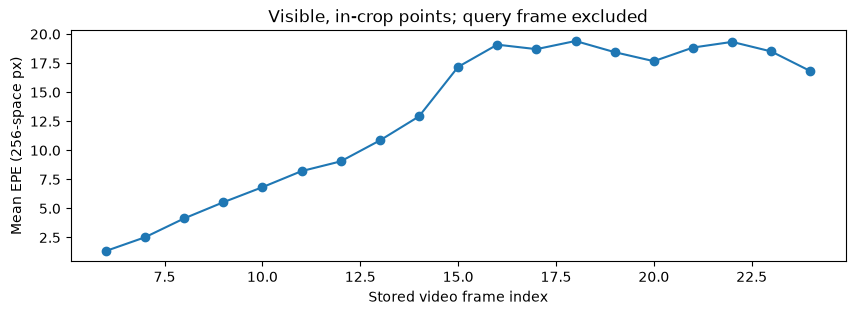

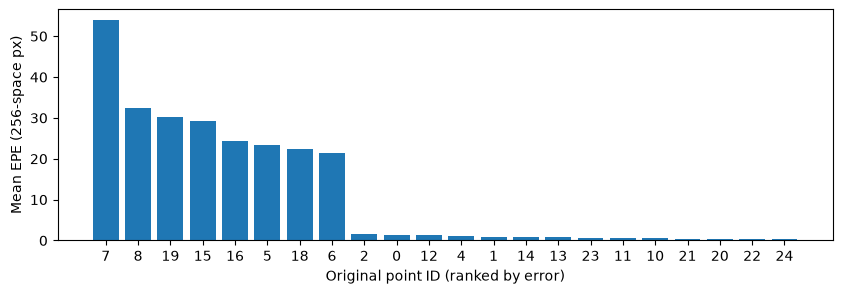

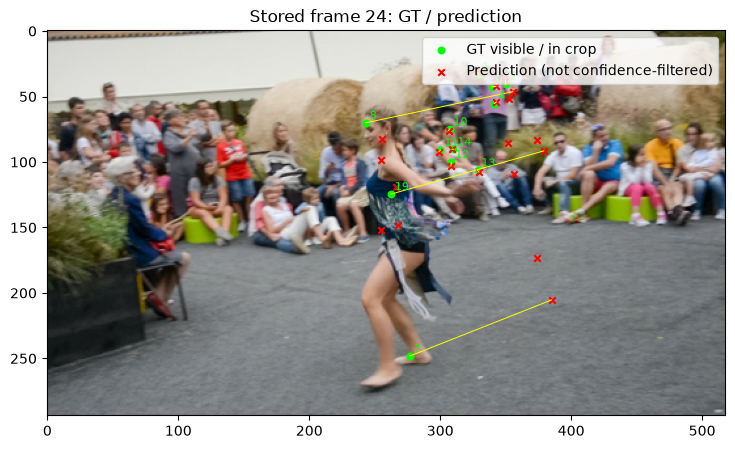

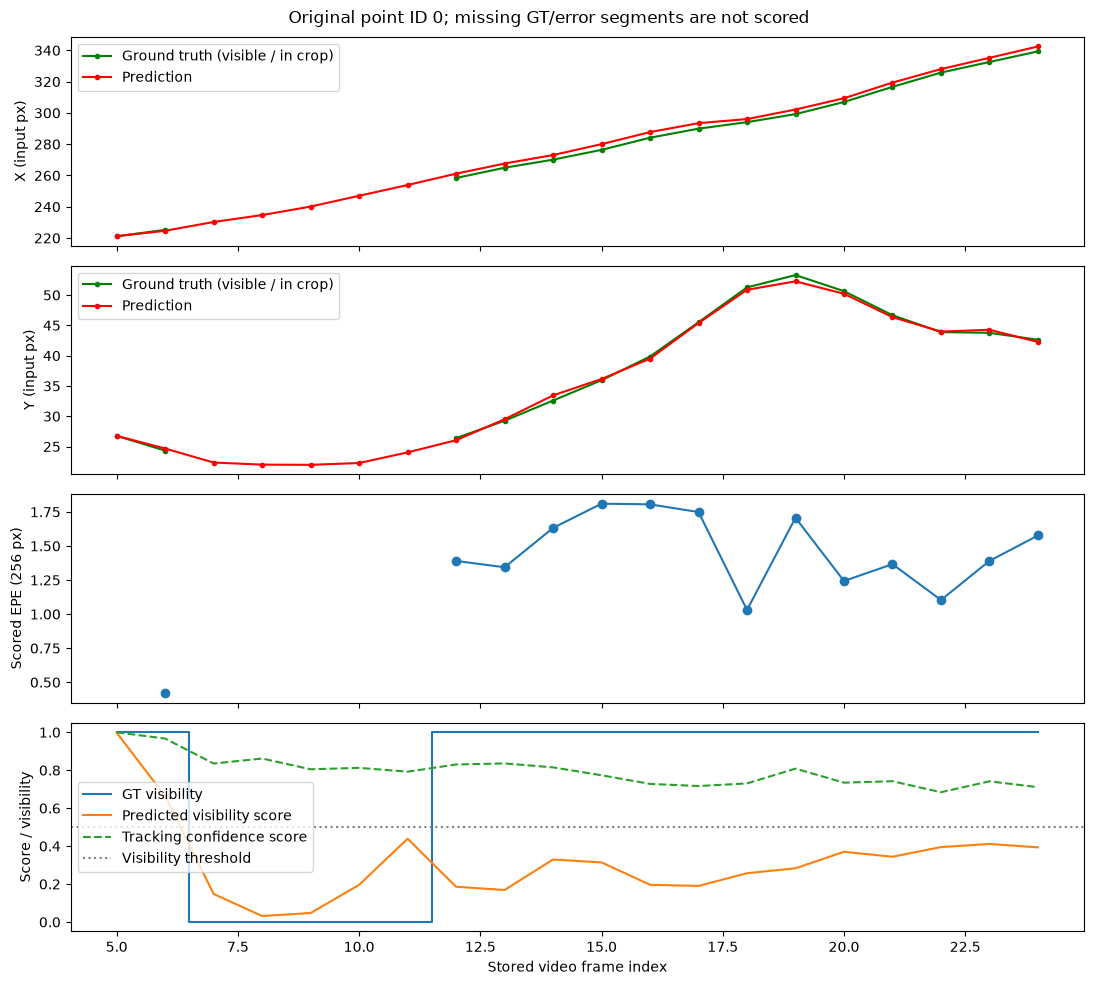

In [7]:
POINT_ID = int(run['annotations']['point_ids'][0])
FRAME_ID = int(run['annotations']['frame_indices'][-1])
for figure in figures.values():
    plt.close(figure)
figures = plot_tracking(run, diag, point_id=POINT_ID, frame_id=FRAME_ID)
plt.show()


## 7. Optional manual point groups
After watching the video, assign **disjoint groups of original point IDs**. For example, separate a rigid object, an articulated/deforming object, and static background. The code does not infer these labels. A moving rigid object is different from a static scene viewed by a moving camera.

Only use IDs tracked in this run. Groups with different numbers of visible frames/points are not perfectly matched experiments; the table shows sample counts. Group means pool valid point/frame pairs. Missing GT during an occlusion cannot establish whether a hidden trajectory is correct.


In [8]:
POINT_GROUPS = {}
# Fill in your own IDs after inspection, for example:
# POINT_GROUPS = {'rigid_object': [...], 'non_rigid_object': [...], 'background': [...]}
if POINT_GROUPS:
    display(HTML(table_html(group_rows(run, diag, POINT_GROUPS), ['group', 'point_ids', 'points', 'scored_pairs', 'mean_epe_256', 'median_epe_256', 'nonfinite_positions', 'visibility_agreement'])))
else:
    print('No groups assigned. No motion classification has been inferred.')


No groups assigned. No motion classification has been inferred.


## 8. Optional comparison of saved runs
Choose completed-run indices from section 1. This loads only small tracking arrays, not another set of RGB/geometry outputs. You can supply manual display labels. Each run's errors are computed on its own scoreable pairs; differences in sequence, window length, temporal context, queries, or preprocessing can change the result.

A timing ratio to the first selected run is provided **only** when export hash, actual annotations, preprocessing, and recorded model/checkpoint match. CPU and CUDA use different inference precision, which is flagged. A 35-frame CPU run versus a 24-frame GPU run is not a controlled speed comparison. Timings exclude loading/preprocessing and should not be treated as robust benchmarks from one run.


In [9]:
COMPARE_RUN_INDICES = []  # For example, two indices with matching input_id and different devices.
COMPARISON_LABELS = {}    # Optional labels keyed by position in this comparison, e.g. {0: 'GPU', 1: 'CPU'}.
comparison_rows = []
if COMPARE_RUN_INDICES:
    if any(i < 0 or i >= len(completed) for i in COMPARE_RUN_INDICES):
        raise ValueError('Choose valid completed-run indices.')
    comparison_rows = compare_runs([completed[i]['path'] for i in COMPARE_RUN_INDICES], diag['threshold'], COMPARISON_LABELS)
    display(HTML(table_html(comparison_rows, ['label', 'sequence', 'frames', 'points', 'scored_pairs', 'device', 'autocast', 'seconds', 'time_ratio_to_first', 'mean_epe_256', 'visibility_agreement'])))
    display(HTML(table_html(comparison_rows, ['label', 'comparison_note'])))
else:
    print('No cross-run comparison selected.')


No cross-run comparison selected.


## 9. Optional geometry inspection
Davis annotations here provide **2D tracking ground truth, not 3D ground truth**. Depth, estimated camera motion, and point clouds are qualitative outputs; this section cannot establish their accuracy. Model confidence is not calibrated correctness. Scene scale is not necessarily metric, and independent runs may need scale/coordinate alignment before geometry comparisons.

This section is disabled by default. NPZ requires decompressing a requested array before taking one frame, so dense maps are loaded one at a time and the selected frame is copied to release the rest. Point maps are optional and subsampled for plotting.


In [10]:
SHOW_GEOMETRY = False
SHOW_POINT_CLOUD = False
GEOMETRY_FRAME_ID = int(run['annotations']['frame_indices'][0])
if SHOW_GEOMETRY:
    additions = plot_geometry(run, GEOMETRY_FRAME_ID, include_points=SHOW_POINT_CLOUD, point_stride=8)
    for name, figure in additions.items():
        if name in figures:
            plt.close(figures[name])
        figures[name] = figure
    plt.show()


## 10. Save analysis when you choose
The next cell saves **every completed run** by default (`SAVE_ALL_RUNS = True`), including separate CPU and GPU runs of the same sequence. It reads and saves one run at a time. To save only the currently selected run, set `SAVE_ALL_RUNS = False` and run the selection cell first. No inference is run.

Each bundle goes to `results/analysis/<sequence>/<run ID>/<experiment>/<save timestamp>/` and contains `tracking.html` (a standalone, offline player with point IDs and position-error labels), PNG graphs, CSV tables, and a JSON summary. Open the HTML in a browser, without Jupyter. No inference files or previous analyses are overwritten.

The currently selected run keeps its plotted figures and optional group/comparison settings if available. Other runs get standard tracking graphs and an overlay of the highest-error example. Dense geometry is not loaded for the bulk export.

Record observations and alternative explanations in `ANALYSIS_NOTES`: e.g. deformation, occlusion, motion blur, camera motion, texture ambiguity. Do not infer a cause from a large tracking error alone. When changing threshold or run, rerun the downstream cells so displayed plots and summaries remain consistent.


In [11]:
SAVE_ALL_RUNS = True  # False saves only the selected run.
ANALYSIS_NOTES = ''  # Applies only to the selected run.
selected_run = globals().get('run')
if SAVE_ALL_RUNS:
    paths_to_save = [Path(row['path']) for row in scan_runs(PROJECT_ROOT / 'results/vggt')
                     if row['status'] == 'completed']
elif selected_run is not None:
    paths_to_save = [selected_run['path']]
else:
    raise ValueError('Select a completed run first, or enable SAVE_ALL_RUNS.')
if not paths_to_save:
    raise FileNotFoundError('No completed runs found.')

saved_analyses = []
threshold = globals().get('VISIBILITY_THRESHOLD', 0.5)
for path in paths_to_save:
    is_selected = selected_run is not None and path == selected_run['path']
    item = selected_run if is_selected else load_run(path, with_images=True)
    output = save_analysis(
        PROJECT_ROOT / 'results/analysis', item, diagnostics(item, threshold),
        figures=globals().get('figures') if is_selected else None,
        point_groups=globals().get('POINT_GROUPS') if is_selected else None,
        comparison_rows=globals().get('comparison_rows') if is_selected else None,
        notes=ANALYSIS_NOTES if is_selected else '',
        fps=globals().get('VIEW_FPS', 10.0), width=globals().get('VIEW_WIDTH', 640),
    )
    saved_analyses.append(output)
    print('Analysis saved:', output)
    del item
del selected_run


Analysis saved: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project/results/vggt_analysis/dance-twirl/20261125T150436_740638Z_09d23a/experiment_001/20261125T153435_674820Z_43c0ed
Analysis saved: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project/results/vggt_analysis/paragliding-launch/20261125T150511_264628Z_19dd0b/experiment_001/20261125T153436_362859Z_3a9682
Analysis saved: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project/results/vggt_analysis/paragliding-launch/20261125T150741_680748Z_cb920c/experiment_001/20261125T153437_125817Z_5a469f
Analysis saved: /home/paul/Documents/Cours/Advanced Machine Learning/AML_project/results/vggt_analysis/dance-twirl/20261125T151026_816269Z_969927/experiment_001/20261125T153437_776135Z_f98a99
